In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split,cross_validate,KFold,RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.base import clone
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

In [2]:
df=pd.read_csv(r"C:\Users\dell\Downloads\startup_data.csv")

In [3]:
df.head()

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status
0,Startup_1,IoT,1,101.09,844.75,67.87,1468,5.20,0,2006,Europe,Private
1,Startup_2,EdTech,1,247.62,3310.83,75.65,3280,8.10,1,2003,South America,Private
2,Startup_3,EdTech,1,109.24,1059.37,84.21,4933,2.61,1,1995,South America,Private
3,Startup_4,Gaming,5,10.75,101.90,47.08,1059,2.53,0,2003,South America,Private
4,Startup_5,IoT,4,249.28,850.11,50.25,1905,4.09,0,1997,Europe,Acquired


In [4]:
df.tail()

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status
495,Startup_496,EdTech,2,181.86,2378.65,59.64,3331,0.58,1,1993,Europe,Private
496,Startup_497,AI,2,107.34,1394.58,10.22,2223,5.85,0,2019,South America,Private
497,Startup_498,E-Commerce,1,160.29,502.09,84.73,2222,4.32,0,2019,Australia,Private
498,Startup_499,Gaming,5,234.65,2814.52,53.16,4972,5.53,0,2011,Europe,Private
499,Startup_500,HealthTech,4,211.76,2563.17,84.19,2374,5.26,0,2000,North America,Private


In [5]:
df.shape

(500, 12)

In [6]:
df.columns

Index(['Startup Name', 'Industry', 'Funding Rounds', 'Funding Amount (M USD)',
       'Valuation (M USD)', 'Revenue (M USD)', 'Employees', 'Market Share (%)',
       'Profitable', 'Year Founded', 'Region', 'Exit Status'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Startup Name            500 non-null    object 
 1   Industry                500 non-null    object 
 2   Funding Rounds          500 non-null    int64  
 3   Funding Amount (M USD)  500 non-null    float64
 4   Valuation (M USD)       500 non-null    float64
 5   Revenue (M USD)         500 non-null    float64
 6   Employees               500 non-null    int64  
 7   Market Share (%)        500 non-null    float64
 8   Profitable              500 non-null    int64  
 9   Year Founded            500 non-null    int64  
 10  Region                  500 non-null    object 
 11  Exit Status             500 non-null    object 
dtypes: float64(4), int64(4), object(4)
memory usage: 47.0+ KB


In [8]:
df.isnull().sum()

Startup Name              0
Industry                  0
Funding Rounds            0
Funding Amount (M USD)    0
Valuation (M USD)         0
Revenue (M USD)           0
Employees                 0
Market Share (%)          0
Profitable                0
Year Founded              0
Region                    0
Exit Status               0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2.958000,152.656760,1371.809180,49.321740,2532.092000,5.092940,0.432000,2006.044000
std,1.440968,86.683711,978.226579,29.267605,1385.434921,2.807646,0.495851,9.347128
min,1.000000,0.570000,2.430000,0.120000,12.000000,0.100000,0.000000,1990.000000
25%,2.000000,79.212500,557.027500,22.802500,1382.750000,2.760000,0.000000,1998.000000
50%,3.000000,156.005000,1222.580000,48.800000,2496.500000,5.135000,0.000000,2006.000000
75%,4.000000,226.450000,2052.085000,74.965000,3708.750000,7.552500,1.000000,2014.000000
max,5.000000,299.810000,4357.490000,99.710000,4984.000000,10.000000,1.000000,2022.000000


In [11]:
df.nunique()

Startup Name              500
Industry                    8
Funding Rounds              5
Funding Amount (M USD)    494
Valuation (M USD)         500
Revenue (M USD)           490
Employees                 478
Market Share (%)          384
Profitable                  2
Year Founded               33
Region                      5
Exit Status                 3
dtype: int64

In [12]:
df[df['Valuation (M USD)'] < 0]

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status


In [13]:
df[df['Revenue (M USD)'] < 0]

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status


In [14]:
df[df['Employees'] < 0]

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status


In [15]:
df[df['Market Share (%)'] < 0]

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status


In [16]:
df[df['Funding Amount (M USD)'] < 0]

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status


In [17]:
df[df['Funding Rounds'] < 0]

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status


In [18]:
cols = ["Funding Rounds","Funding Amount (M USD)","Valuation (M USD)","Employees","Market Share (%)"]

print((df[cols] < 0).any())
print((df[cols] < 0).sum())

Funding Rounds            False
Funding Amount (M USD)    False
Valuation (M USD)         False
Employees                 False
Market Share (%)          False
dtype: bool
Funding Rounds            0
Funding Amount (M USD)    0
Valuation (M USD)         0
Employees                 0
Market Share (%)          0
dtype: int64


In [19]:
(df["Valuation (M USD)"] == 0).reset_index()

,index,Valuation (M USD)
0,0,False
1,1,False
2,2,False
3,3,False
4,4,False
...,...,...
495,495,False
496,496,False
497,497,False
498,498,False


In [20]:
print("Earliest founding year:", df["Year Founded"].min())
print("Latest founding year:", df["Year Founded"].max())

Earliest founding year: 1990
Latest founding year: 2022


In [21]:
df["Market Share (%)"].between(0, 100)

0      True
1      True
2      True
3      True
4      True
       ... 
495    True
496    True
497    True
498    True
499    True
Name: Market Share (%), Length: 500, dtype: bool

In [22]:
(~df["Market Share (%)"].between(0, 100)).any()

np.False_

In [23]:
print(df["Profitable"].unique())

[0 1]


In [24]:
print(df["Industry"].value_counts())
print(df["Region"].value_counts())
print(df["Exit Status"].value_counts())

Industry
EdTech           74
FinTech          71
E-Commerce       70
Gaming           62
AI               62
IoT              61
Cybersecurity    51
HealthTech       49
Name: count, dtype: int64
Region
Australia        108
Asia             103
Europe           102
North America     97
South America     90
Name: count, dtype: int64
Exit Status
Private     348
Acquired    107
IPO          45
Name: count, dtype: int64


In [25]:
skewness = df["Valuation (M USD)"].skew()

print("Skewness:", skewness)

Skewness: 0.6926824558637932


In [26]:
# 1. Inspect exit-status categories
print("Exit Status categories:")
print(df["Exit Status"].value_counts(dropna=False))

# 2. Compare valuation across exit statuses
print("\nAverage valuation by Exit Status:")
print(
    df.groupby("Exit Status")["Valuation (M USD)"]
      .agg(["count", "mean", "median"])
)

# 3. Investigate potential target leakage
print("\nLeakage Investigation:")
print(
    "Prediction target: Valuation (M USD)\n"
    "Feature under investigation: Exit Status\n"
    "Key question: Was Exit Status known at the time the valuation prediction "
    "would have been made?\n"
    "If Exit Status records a subsequent IPO, acquisition, or closure, "
    "it contains future information and must be excluded.\n"
    "If Exit Status was already known at prediction time, it may be used, "
    "provided it does not otherwise reveal the target.\n"
)

# 4. Conclusion
print("Conclusion:")
print(
    "Exclude Exit Status from the valuation-prediction model unless its "
    "availability at the prediction date can be verified. If it reflects "
    "events occurring after the valuation date, including it would cause "
    "target leakage."
)

Exit Status categories:
Exit Status
Private     348
Acquired    107
IPO          45
Name: count, dtype: int64

Average valuation by Exit Status:
             count         mean   median
Exit Status                             
Acquired       107  1441.042991  1310.73
IPO             45  1402.865556  1192.96
Private        348  1346.505862  1210.40

Leakage Investigation:
Prediction target: Valuation (M USD)
Feature under investigation: Exit Status
Key question: Was Exit Status known at the time the valuation prediction would have been made?
If Exit Status records a subsequent IPO, acquisition, or closure, it contains future information and must be excluded.
If Exit Status was already known at prediction time, it may be used, provided it does not otherwise reveal the target.

Conclusion:
Exclude Exit Status from the valuation-prediction model unless its availability at the prediction date can be verified. If it reflects events occurring after the valuation date, including it would cause

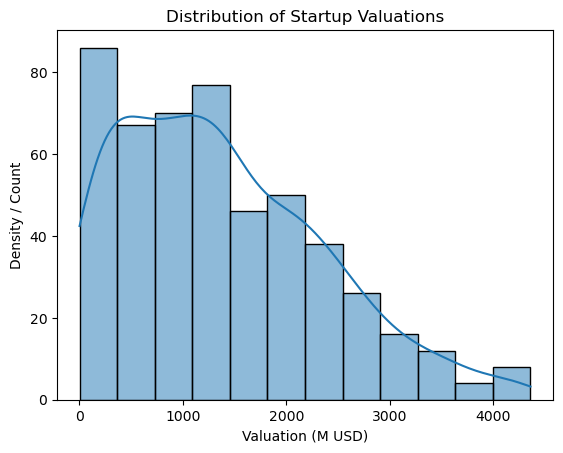

In [27]:
sns.histplot(df["Valuation (M USD)"], kde=True)

plt.title("Distribution of Startup Valuations")
plt.xlabel("Valuation (M USD)")
plt.ylabel("Density / Count")
plt.show()

<Axes: ylabel='Valuation (M USD)'>

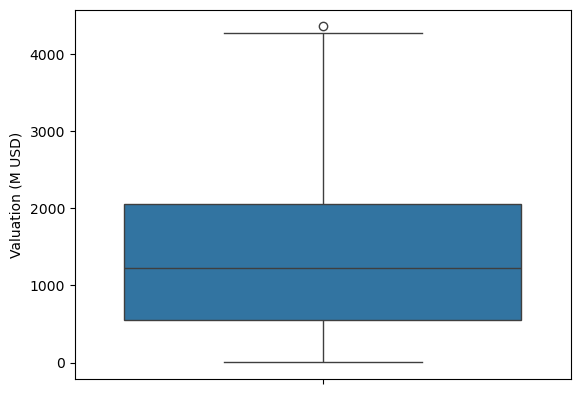

In [28]:
sns.boxplot(df["Valuation (M USD)"])

In [29]:
valuation = df["Valuation (M USD)"]

In [30]:
print("Valuation Distribution Statistics")
print("---------------------------------")
print("Mean:", valuation.mean())
print("Median:", valuation.median())
print("Minimum:", valuation.min())
print("Maximum:", valuation.max())
print("Standard Deviation:", valuation.std())
print("Skewness:", valuation.skew())

Valuation Distribution Statistics
---------------------------------
Mean: 1371.8091800000002
Median: 1222.58
Minimum: 2.43
Maximum: 4357.49
Standard Deviation: 978.2265786779624
Skewness: 0.6926824558637932


In [31]:
Q1 = df["Valuation (M USD)"].describe()["25%"]
Q3 = df["Valuation (M USD)"].describe()["75%"]
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = valuation[
    (valuation < lower_bound) | (valuation > upper_bound)
]

print("\nOutlier Analysis")
print("----------------")
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))


Outlier Analysis
----------------
Lower bound: -1685.5587500000004
Upper bound: 4294.67125
Number of outliers: 1


In [32]:
skewness = valuation.skew()

print("\nDistribution Interpretation")
print("---------------------------")
print("Skewness:",skewness)
if skewness > 0.5:
    print("The distribution is right-skewed.")
elif skewness < -0.5:
    print("The distribution is left-skewed.")
else:
    print("The distribution is approximately symmetric.")


Distribution Interpretation
---------------------------
Skewness: 0.6926824558637932
The distribution is right-skewed.


In [33]:
print("\nLog Transformation Assessment")
print("-----------------------------")

if (valuation >= 0).all() and skewness > 1:
    print("A log transformation may be worth testing during modeling.")
elif (valuation >= 0).all() and skewness > 0.5:
    print("Consider testing a log transformation during modeling.")
else:
    print("A log transformation may not be necessary based on skewness alone.")

print("The original valuation data has not been transformed.")


Log Transformation Assessment
-----------------------------
Consider testing a log transformation during modeling.
The original valuation data has not been transformed.


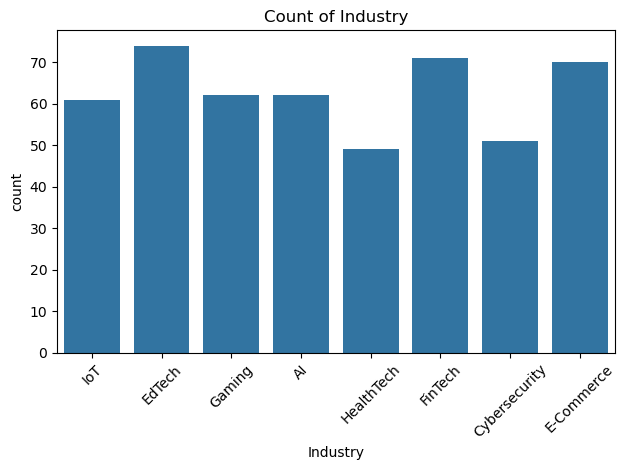

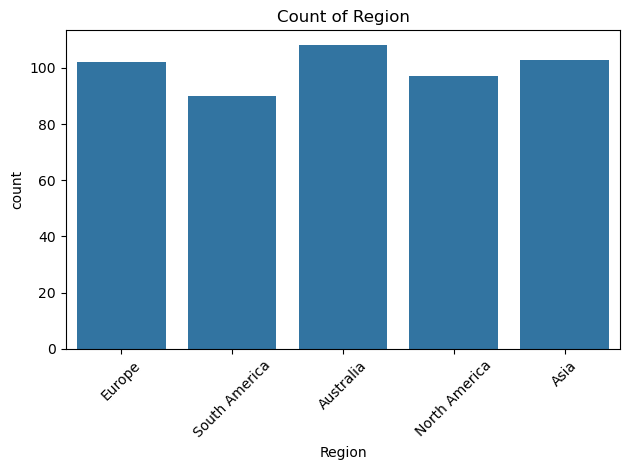

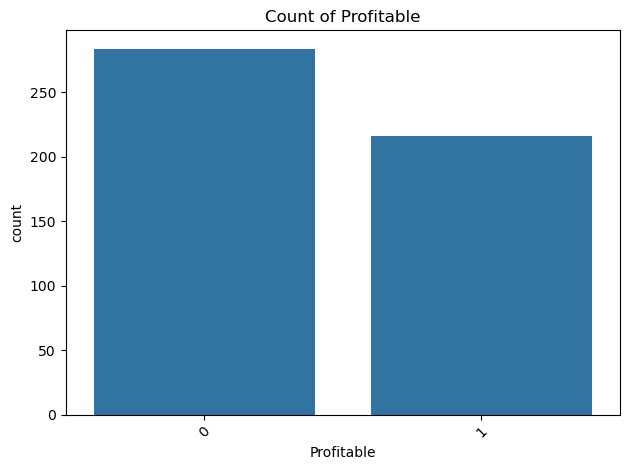

In [34]:
for col in ['Industry', 'Region', 'Profitable']:
    sns.countplot(data=df, x=col)
    plt.title(f'Count of {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


Valuation by Industry:
                Median      Q1       Q3      IQR
Industry                                        
Gaming         1490.52  944.99  2244.21  1299.22
E-Commerce     1469.39  547.62  2421.26  1873.64
EdTech         1229.94  683.80  2032.44  1348.64
FinTech        1209.81  832.52  1984.29  1151.78
Cybersecurity  1139.08  638.14  2394.42  1756.28
IoT            1090.83  472.04  1776.82  1304.78
AI             1018.26  340.54  1720.32  1379.78
HealthTech      953.33  421.00  1950.63  1529.63


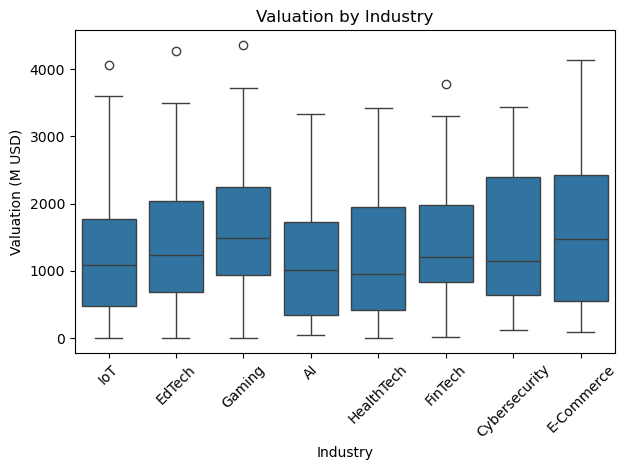


Valuation by Region:
                Median      Q1       Q3      IQR
Region                                          
North America  1442.91  671.71  2131.92  1460.21
South America  1327.91  732.40  2052.63  1320.23
Asia           1183.34  561.86  2131.96  1570.10
Australia      1159.37  551.04  1911.26  1360.22
Europe         1046.55  505.76  1742.21  1236.45


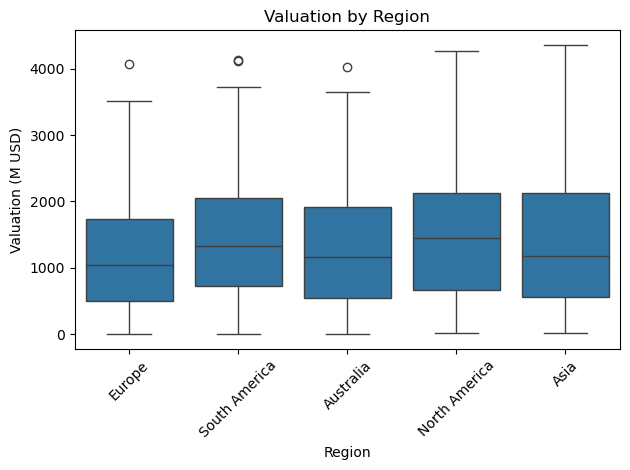


Valuation by Profitable:
             Median      Q1       Q3      IQR
Profitable                                   
1           1338.38  584.98  2191.49  1606.51
0           1160.86  551.04  1881.74  1330.70


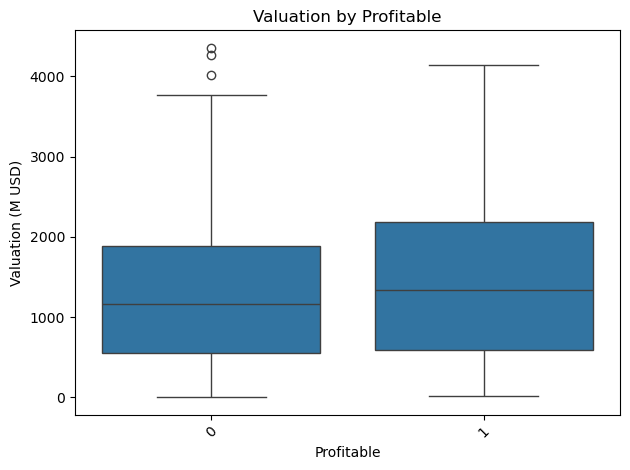

In [35]:
for col in ['Industry', 'Region', 'Profitable']:
    print(f"\nValuation by {col}:")

    summary = df.groupby(col)['Valuation (M USD)'].agg(
        Median='median',
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )

    summary['IQR'] = summary['Q3'] - summary['Q1']
    print(summary.sort_values('Median', ascending=False).round(2))

    sns.boxplot(data=df, x=col, y='Valuation (M USD)')
    plt.title(f'Valuation by {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Industry: Gaming has the highest median valuation (1,490.52 M USD); HealthTech has the lowest (953.33 M USD). E-Commerce has the widest IQR (1,873.64 M USD), so valuations there vary the most.

Region: North America has the highest median (1,442.91 M USD); Europe has the lowest (1,046.55 M USD). Asia has the widest IQR (1,570.10 M USD).

Profitability: Profitable startups have a higher median valuation (1,338.38 M USD) than non-profitable startups (1,160.86 M USD). This shows an association, not proof that profitability causes higher valuation.

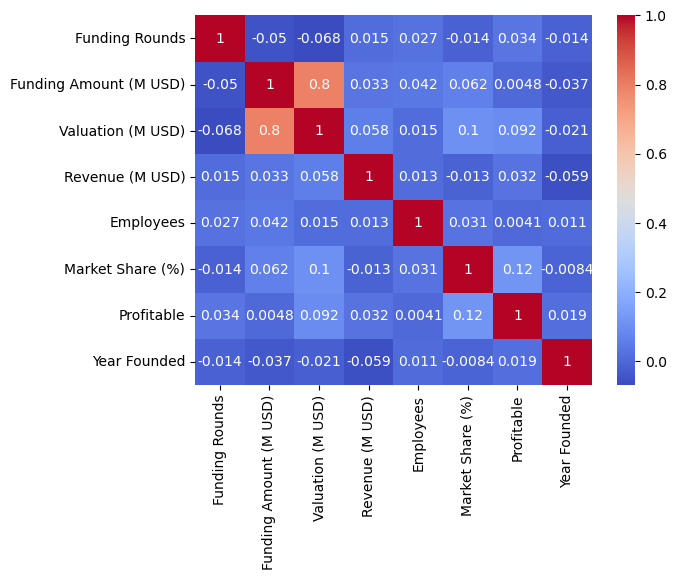

In [36]:
num = df.select_dtypes(include='number').drop(
    columns=['Exit Status'], errors='ignore'
)

sns.heatmap(num.corr(), annot=True, cmap='coolwarm')
plt.show()

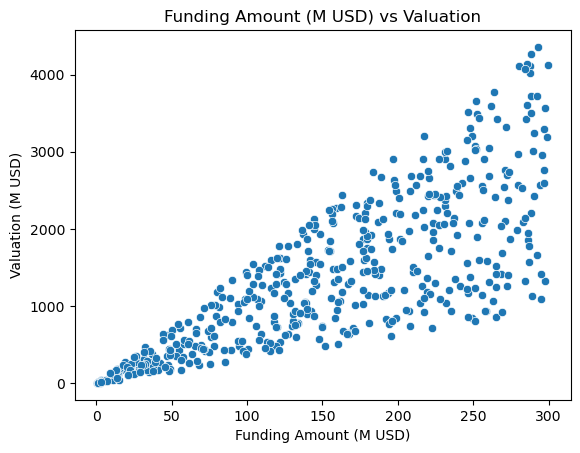

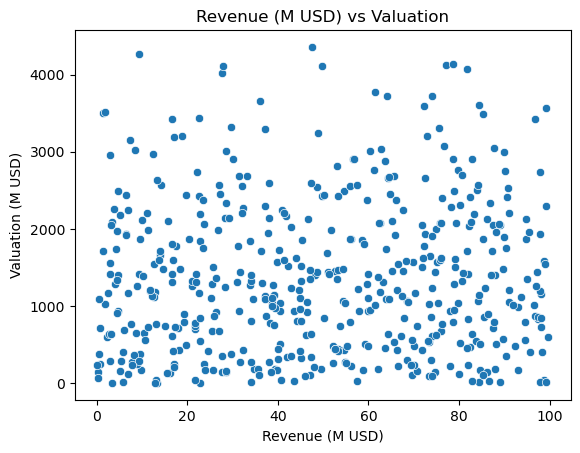

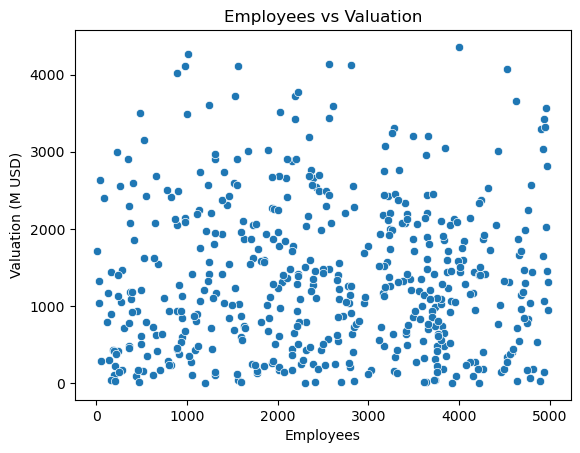

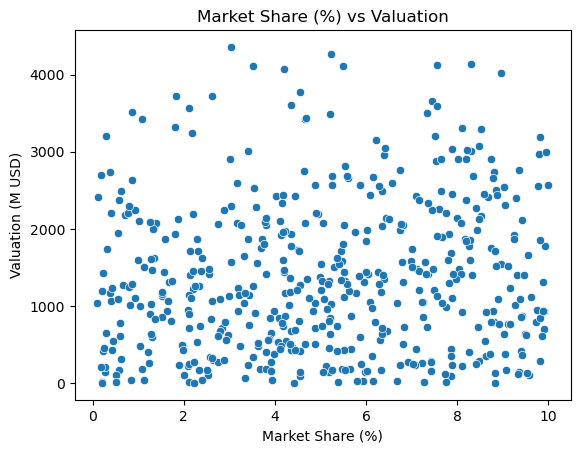

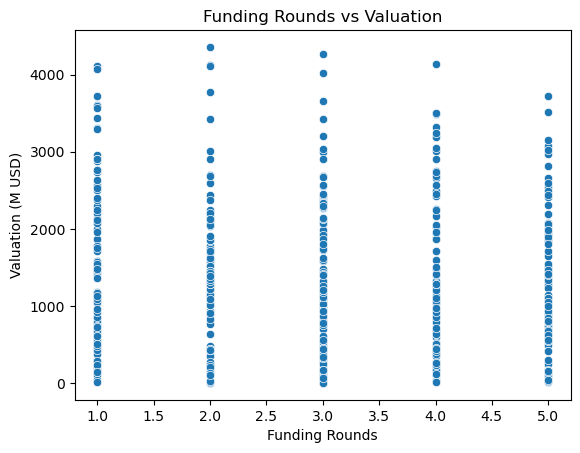

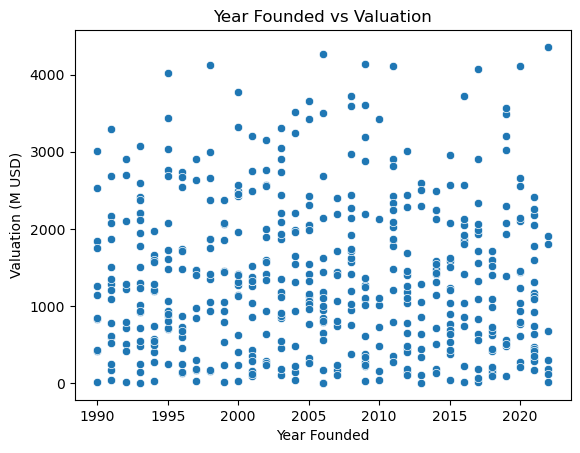

In [37]:
for col in ["Funding Amount (M USD)","Revenue (M USD)","Employees","Market Share (%)","Funding Rounds","Year Founded"]:
    sns.scatterplot(data=df,x=col,y="Valuation (M USD)")
    plt.title(f'{col} vs Valuation')
    plt.show()

In [38]:
print(
    num.corr()['Valuation (M USD)']
    .drop('Valuation (M USD)')
    .sort_values(ascending=False)
)

Funding Amount (M USD)    0.795061
Market Share (%)          0.103547
Profitable                0.092499
Revenue (M USD)           0.058219
Employees                 0.014660
Year Founded             -0.021101
Funding Rounds           -0.067821
Name: Valuation (M USD), dtype: float64


Funding Amount has a strong positive correlation with valuation (r = 0.795); it is the strongest numerical relationship and should be an important model feature.

Market Share (r = 0.104) and Profitable (r = 0.092) have very weak positive relationships.
Revenue (r = 0.058) and Employees (r = 0.015) have negligible linear relationships.

Year Founded (r = −0.021) and Funding Rounds (r = −0.068) have negligible weak negative relationships.

The scatter plots should be used to note whether a relationship looks broadly linear or mostly scattered; only the funding-versus-valuation relationship is expected to show a strong visible trend.

These are associations only and do not demonstrate causation.

In [39]:
df.head()

,Startup Name,Industry,Funding Rounds,Funding Amount (M USD),Valuation (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region,Exit Status
0,Startup_1,IoT,1,101.09,844.75,67.87,1468,5.20,0,2006,Europe,Private
1,Startup_2,EdTech,1,247.62,3310.83,75.65,3280,8.10,1,2003,South America,Private
2,Startup_3,EdTech,1,109.24,1059.37,84.21,4933,2.61,1,1995,South America,Private
3,Startup_4,Gaming,5,10.75,101.90,47.08,1059,2.53,0,2003,South America,Private
4,Startup_5,IoT,4,249.28,850.11,50.25,1905,4.09,0,1997,Europe,Acquired


In [40]:
y=df["Valuation (M USD)"]

In [41]:
X=df.drop(columns=["Startup Name","Valuation (M USD)","Exit Status"])

In [42]:
X.head()

,Industry,Funding Rounds,Funding Amount (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region
0,IoT,1,101.09,67.87,1468,5.20,0,2006,Europe
1,EdTech,1,247.62,75.65,3280,8.10,1,2003,South America
2,EdTech,1,109.24,84.21,4933,2.61,1,1995,South America
3,Gaming,5,10.75,47.08,1059,2.53,0,2003,South America
4,IoT,4,249.28,50.25,1905,4.09,0,1997,Europe


In [43]:
X.columns

Index(['Industry', 'Funding Rounds', 'Funding Amount (M USD)',
       'Revenue (M USD)', 'Employees', 'Market Share (%)', 'Profitable',
       'Year Founded', 'Region'],
      dtype='object')

In [44]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Industry                500 non-null    object 
 1   Funding Rounds          500 non-null    int64  
 2   Funding Amount (M USD)  500 non-null    float64
 3   Revenue (M USD)         500 non-null    float64
 4   Employees               500 non-null    int64  
 5   Market Share (%)        500 non-null    float64
 6   Profitable              500 non-null    int64  
 7   Year Founded            500 non-null    int64  
 8   Region                  500 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 35.3+ KB


In [45]:
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,test_size=0.2,random_state=42)

In [46]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(400, 9)
(100, 9)
(400,)
(100,)


In [47]:
print(y_train.mean())
print(y_train.median())
print(y_test.mean())
print(y_test.median())

1372.8533250000003
1213.4299999999998
1367.6326000000001
1251.7150000000001


In [48]:
X.head(10)

,Industry,Funding Rounds,Funding Amount (M USD),Revenue (M USD),Employees,Market Share (%),Profitable,Year Founded,Region
0,IoT,1,101.09,67.87,1468,5.20,0,2006,Europe
1,EdTech,1,247.62,75.65,3280,8.10,1,2003,South America
2,EdTech,1,109.24,84.21,4933,2.61,1,1995,South America
3,Gaming,5,10.75,47.08,1059,2.53,0,2003,South America
4,IoT,4,249.28,50.25,1905,4.09,0,1997,Europe
5,AI,5,103.89,12.56,1462,8.96,1,2004,Europe
6,Gaming,4,232.26,38.60,1404,0.10,0,2016,Australia
7,HealthTech,5,109.15,64.37,3420,9.02,1,2002,Australia
8,Gaming,5,258.39,78.06,447,1.62,0,2020,North America
9,FinTech,3,66.24,21.80,3655,9.90,0,1995,Europe


In [49]:
cat_cols = ["Industry", "Region"]

num_cols = ["Funding Rounds", "Funding Amount (M USD)", "Revenue (M USD)",
            "Employees", "Market Share (%)", "Year Founded"]

In [50]:
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
    ("binary", "passthrough", ["Profitable"])
])

In [51]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [52]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (400, 20)
X_test shape: (100, 20)


In [53]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [54]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

In [55]:
print("Train MAE:", mean_absolute_error(y_train, train_pred))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, train_pred)))
print("Train R2:", r2_score(y_train, train_pred))

print("Test MAE:", mean_absolute_error(y_test, test_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))
print("Test R2:", r2_score(y_test, test_pred))

Train MAE: 450.17155009137997
Train RMSE: 581.8000192961948
Train R2: 0.6430699849955293
Test MAE: 426.7107237722789
Test RMSE: 567.8958446204102
Test R2: 0.671476513229432


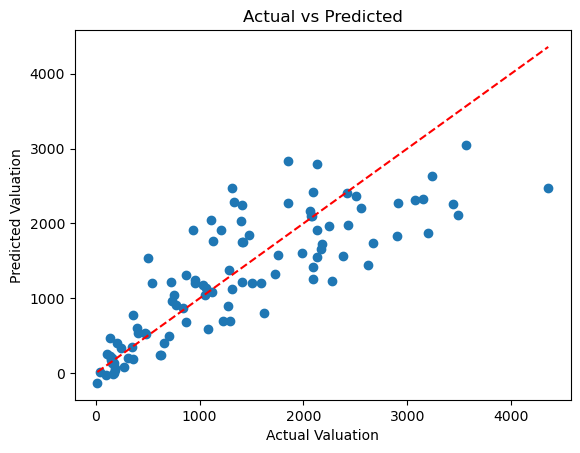

In [56]:
plt.scatter(y_test, test_pred)
plt.xlabel("Actual Valuation")
plt.ylabel("Predicted Valuation")
plt.title("Actual vs Predicted")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], "r--")
plt.show()

Training Performance: MAE = 450.17, RMSE = 581.80, R² = 0.643.

Testing Performance: MAE = 426.71, RMSE = 567.90, R² = 0.671.

Overfitting: There is no clear evidence of overfitting because the training and testing metrics are very similar.

Model Performance: The model explains approximately 67.1% of the variation in test-set valuations. Further improvement may be possible.

Actual vs. Predicted Plot: The scatter plot shows how closely the predicted valuations match the actual valuations. Points closer to the diagonal reference line indicate more accurate predictions.

Conclusion: The baseline Linear Regression model performs reasonably well on the test data and provides a useful starting point for comparing more advanced models.

In [57]:
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [58]:
train_pred = rf.predict(X_train)
test_pred = rf.predict(X_test)

In [59]:
print("Train MAE:", mean_absolute_error(y_train, train_pred))
print("Train RMSE:", np.sqrt(mean_squared_error(y_train, train_pred)))
print("Train R2:", r2_score(y_train, train_pred))

print("Test MAE:", mean_absolute_error(y_test, test_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))
print("Test R2:", r2_score(y_test, test_pred))

Train MAE: 166.7321298750001
Train RMSE: 228.24541544222913
Train R2: 0.9450661884109761
Test MAE: 428.73117450000007
Test RMSE: 593.2623664168794
Test R2: 0.6414723609388675


### Random Forest Results and Comparison

The initial Random Forest model shows strong training performance, with an R² score of 0.945 and an MAE of 166.73 M USD. However, its test performance decreases substantially: test R² is 0.641, test MAE is 428.73 M USD, and test RMSE is 593.26 M USD.

Compared with Linear Regression, Random Forest performs slightly worse on the test set. Linear Regression achieved a higher test R² of 0.671 and lower test errors (MAE = 426.71 M USD; RMSE = 567.90 M USD).

The large gap between Random Forest training and test performance indicates overfitting. Therefore, the current untuned Random Forest model is not the preferred model. It may still improve through cross-validation and hyperparameter tuning.

In [60]:
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [61]:
train_pred = gb.predict(X_train)
test_pred = gb.predict(X_test)

In [62]:
for name, actual, pred in [
    ("Train", y_train, train_pred),
    ("Test", y_test, test_pred)
]:
    print(name, "MAE:", mean_absolute_error(actual, pred))
    print(name, "RMSE:", np.sqrt(mean_squared_error(actual, pred)))
    print(name, "R2:", r2_score(actual, pred))

Train MAE: 245.4626447236429
Train RMSE: 322.63816057204866
Train R2: 0.8902341932713114
Test MAE: 436.3140247959764
Test RMSE: 619.5895690498369
Test R2: 0.6089455456514318


### Gradient Boosting Results and Model Comparison

The Gradient Boosting model achieved a training R² score of 0.890, but its test R² decreased to 0.609. Its test MAE was 436.31 M USD and its test RMSE was 619.59 M USD.

This model performs worse on the test set than both Linear Regression and Random Forest. The gap between training and test results also indicates overfitting.

Among the three models tested so far, Linear Regression remains the best model. It has the highest test R² score (0.671) and the lowest test MAE (426.71 M USD) and RMSE (567.90 M USD).

This comparison shows that more advanced models do not automatically produce better results. With the current dataset and default settings, Linear Regression generalizes best.

In [63]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [64]:
cat_cols = ["Industry", "Region"]

num_cols = [
    "Funding Rounds",
    "Funding Amount (M USD)",
    "Revenue (M USD)",
    "Employees",
    "Market Share (%)",
    "Year Founded"
]

In [65]:
cv_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("numerical", StandardScaler(), num_cols),
    ("binary", "passthrough", ["Profitable"])
])

In [66]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

In [67]:
cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_comparison = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", cv_preprocessor),
        ("model", model)
    ])

    cv_results = cross_validate(
        pipeline,
        X_train_raw,
        y_train_raw,
        cv=cv_strategy,
        scoring={
            "r2": "r2",
            "rmse": "neg_root_mean_squared_error"
        }
    )


    r2_scores = cv_results["test_r2"]
    rmse_scores = -cv_results["test_rmse"]

    cv_comparison.append({
        "Model": model_name,
        "Mean CV R²": r2_scores.mean(),
        "Std R²": r2_scores.std(),
        "Mean CV RMSE": rmse_scores.mean(),
        "Std RMSE": rmse_scores.std()
    })


cv_comparison_df = pd.DataFrame(cv_comparison)

cv_comparison_df = cv_comparison_df.sort_values(
    by="Mean CV R²",
    ascending=False
).reset_index(drop=True)

display(cv_comparison_df.round(4))

,Model,Mean CV R²,Std R²,Mean CV RMSE,Std RMSE
0,Gradient Boosting,0.6087,0.0635,600.1174,35.6064
1,Linear Regression,0.6060,0.0507,604.7686,50.1648
2,Random Forest,0.5972,0.0552,609.9029,32.4339


In [68]:
pipe = Pipeline([
    ("preprocessor", cv_preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

In [69]:
params = {
    "model__n_estimators": [50, 100, 150, 200, 300],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.8, 0.9, 1.0]
}

In [70]:
search = RandomizedSearchCV(
    pipe,
    param_distributions=params,
    n_iter=30,
    cv=cv_strategy,
    scoring="r2",
    random_state=42,
    n_jobs=-1
)

In [71]:
search.fit(X_train_raw, y_train_raw)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [2, 3, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,n_iter,30
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [72]:
print("Best parameters:", search.best_params_)
print("Best CV R2:", search.best_score_)
print("Original CV R2:", 0.6087)
print("Improvement:", search.best_score_ - 0.6087)

Best parameters: {'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_depth': 3, 'model__learning_rate': 0.01}
Best CV R2: 0.604557208348147
Original CV R2: 0.6087
Improvement: -0.0041427916518530505


In [73]:
pipe_rf = Pipeline([
    ("preprocessor", cv_preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

In [74]:
params_rf = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 0.7, 1.0]
}

In [75]:
search_rf = RandomizedSearchCV(
    pipe_rf,
    param_distributions=params_rf,
    n_iter=30,
    cv=cv_strategy,
    scoring="r2",
    random_state=42,
    n_jobs=-1
)

In [76]:
search_rf.fit(X_train_raw, y_train_raw)

print("Best parameters:", search_rf.best_params_)
print("Best CV R2:", search_rf.best_score_)
print("Original CV R2:", 0.5972)
print("Improvement:", search_rf.best_score_ - 0.5972)

Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': 10}
Best CV R2: 0.6089704788906258
Original CV R2: 0.5972
Improvement: 0.01177047889062588


In [77]:
selected_models = {
    "Linear Regression": LinearRegression(),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "Tuned Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=42
    )
}

In [78]:
final_results = []

for model_name, model in selected_models.items():

    pipeline = Pipeline([
        ("preprocessor", cv_preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train_raw, y_train_raw)

    y_train_pred = pipeline.predict(X_train_raw)
    y_test_pred = pipeline.predict(X_test_raw)

    train_r2 = r2_score(y_train_raw, y_train_pred)
    test_r2 = r2_score(y_test_raw, y_test_pred)

    test_mae = mean_absolute_error(y_test_raw, y_test_pred)

    test_rmse = np.sqrt(
        mean_squared_error(y_test_raw, y_test_pred)
    )
    final_results.append({
        "Model": model_name,
        "Train R²": train_r2,
        "Test R²": test_r2,
        "Test MAE": test_mae,
        "Test RMSE": test_rmse
    })

In [79]:
final_comparison_df = pd.DataFrame(final_results)

In [80]:
final_comparison_df = final_comparison_df.sort_values(
    by="Test R²",
    ascending=False
).reset_index(drop=True)

In [81]:
display(final_comparison_df.round(4))

,Model,Train R²,Test R²,Test MAE,Test RMSE
0,Linear Regression,0.6431,0.6715,426.7107,567.8958
1,Tuned Random Forest,0.8544,0.6419,429.1447,592.9245
2,Gradient Boosting,0.8902,0.6089,436.3140,619.5896


In [82]:
best_model_name = final_comparison_df.iloc[0]["Model"]

print("Best Test-Performing Model:", best_model_name)

Best Test-Performing Model: Linear Regression


In [83]:
X_ann_train, X_ann_val, y_ann_train, y_ann_val = train_test_split(
    X_train_raw,
    y_train_raw,
    test_size=0.2,
    random_state=42
)

print("ANN Training Shape:", X_ann_train.shape)
print("ANN Validation Shape:", X_ann_val.shape)
print("Original Test Shape:", X_test_raw.shape)

ANN Training Shape: (320, 9)
ANN Validation Shape: (80, 9)
Original Test Shape: (100, 9)


In [84]:
ann_preprocessor = clone(cv_preprocessor)

X_ann_train_processed = ann_preprocessor.fit_transform(X_ann_train)

X_ann_val_processed = ann_preprocessor.transform(X_ann_val)

if hasattr(X_ann_train_processed, "toarray"):
    X_ann_train_processed = X_ann_train_processed.toarray()

if hasattr(X_ann_val_processed, "toarray"):
    X_ann_val_processed = X_ann_val_processed.toarray()

X_ann_train_processed = np.asarray(
    X_ann_train_processed,
    dtype=np.float32
)

X_ann_val_processed = np.asarray(
    X_ann_val_processed,
    dtype=np.float32
)

y_ann_train = np.asarray(y_ann_train, dtype=np.float32)
y_ann_val = np.asarray(y_ann_val, dtype=np.float32)

print("Processed Training Shape:", X_ann_train_processed.shape)
print("Processed Validation Shape:", X_ann_val_processed.shape)

Processed Training Shape: (320, 20)
Processed Validation Shape: (80, 20)


In [85]:
input_dim = X_ann_train_processed.shape[1]

print("ANN Input Features:", input_dim)

ANN Input Features: 20


In [86]:
ann_model = Sequential([
    
    Input(shape=(input_dim,)),

    Dense(64, activation="relu"),

    Dense(32, activation="relu"),

    Dense(16, activation="relu"),

    Dense(1, activation="linear")
])

In [87]:
ann_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [88]:
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           1,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

In [89]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

In [90]:
history = ann_model.fit(X_ann_train_processed,y_ann_train,validation_data=(X_ann_val_processed,y_ann_val),epochs=200,batch_size=32,callbacks=[early_stopping],verbose=1)

Epoch 1/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - loss: 2992419.7500 - mae: 1423.4490 - val_loss: 2193810.5000 - val_mae: 1169.7201
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 2991267.0000 - mae: 1423.0549 - val_loss: 2192825.5000 - val_mae: 1169.2915
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 2989701.5000 - mae: 1422.5243 - val_loss: 2191263.0000 - val_mae: 1168.6196
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 2987148.5000 - mae: 1421.6599 - val_loss: 2188660.0000 - val_mae: 1167.5159
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 2982851.5000 - mae: 1420.2230 - val_loss: 2184256.5000 - val_mae: 1165.7074
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2975590.2500 - mae: 1417.8245 - val_loss: 2176799.0000 - val_mae: 1162.6901
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2963399.5000 - mae: 1413.8535 - val_loss: 2164490.5000 - val_mae: 1157.7682
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/s

In [91]:
epochs_trained = len(history.history["loss"])
best_epoch = np.argmin(history.history["val_loss"]) + 1
best_val_loss = min(history.history["val_loss"])

print("Epochs trained:", epochs_trained)
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

Epochs trained: 100
Best epoch: 85
Best validation loss: 283334.8125
Final training loss: 347991.5
Final validation loss: 284020.9375


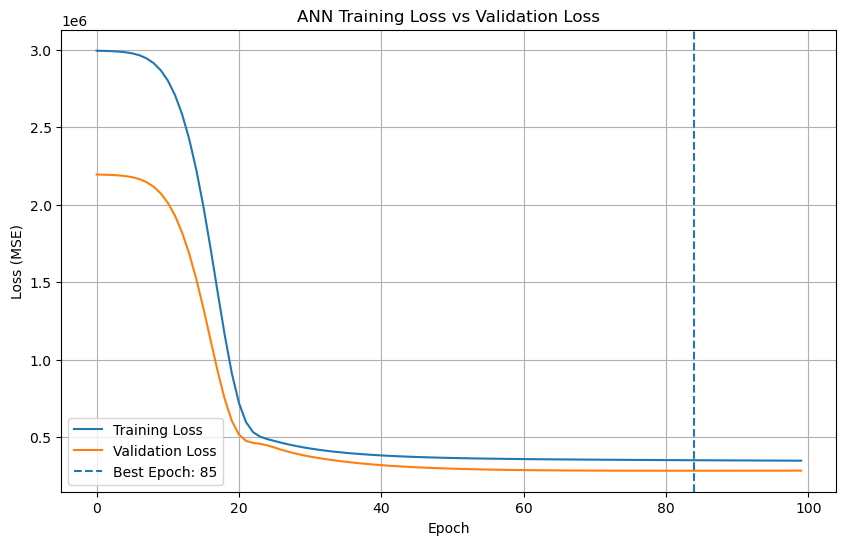

In [92]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("ANN Training Loss vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [93]:
y_ann_val_pred = ann_model.predict(
    X_ann_val_processed,
    verbose=0
).ravel()

y_ann_val_actual = np.asarray(y_ann_val).ravel()

r2 = r2_score(
    y_ann_val_actual,
    y_ann_val_pred
)

mae = mean_absolute_error(
    y_ann_val_actual,
    y_ann_val_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_ann_val_actual,
        y_ann_val_pred
    )
)

ann_val_results = pd.DataFrame({
    "Model": ["ANN"],
    "R2": [r2],
    "MAE": [mae],
    "RMSE": [rmse]
})

display(ann_val_results.round(4))

,Model,R2,MAE,RMSE
0,ANN,0.6568,442.3972,532.292


In [94]:
train_loss = history.history["loss"][best_epoch - 1]
val_loss = history.history["val_loss"][best_epoch - 1]

print("Training loss at best epoch:", train_loss)
print("Validation loss at best epoch:", val_loss)

if val_loss > train_loss * 1.5:
    print("Possible overfitting: validation loss is much higher than training loss.")
elif train_loss > val_loss * 1.5:
    print("Training loss is much higher than validation loss. Check for underfitting or differences in the data.")
else:
    print("No strong overfitting signal based on this simple loss comparison.")

Training loss at best epoch: 351063.875
Validation loss at best epoch: 283334.8125
No strong overfitting signal based on this simple loss comparison.


In [95]:
ml_models = {
    "Linear Regression": LinearRegression(),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "Tuned Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=42
    )
}

In [96]:
validation_results = []

In [97]:
for model_name, model in ml_models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(cv_preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_ann_train, y_ann_train)

    y_val_pred = pipeline.predict(X_ann_val)

    val_r2 = r2_score(y_ann_val, y_val_pred)

    val_mae = mean_absolute_error(y_ann_val, y_val_pred)

    val_rmse = np.sqrt(
        mean_squared_error(y_ann_val, y_val_pred)
    )

    validation_results.append({
        "Model": model_name,
        "Validation R²": val_r2,
        "Validation MAE": val_mae,
        "Validation RMSE": val_rmse
    })

In [98]:
ann_val_pred = ann_model.predict(
    X_ann_val_processed,
    verbose=0
).flatten()

ann_val_r2 = r2_score(y_ann_val, ann_val_pred)

ann_val_mae = mean_absolute_error(y_ann_val, ann_val_pred)

ann_val_rmse = np.sqrt(
    mean_squared_error(y_ann_val, ann_val_pred)
)

In [99]:
validation_results.append({
    "Model": "Artificial Neural Network",
    "Validation R²": ann_val_r2,
    "Validation MAE": ann_val_mae,
    "Validation RMSE": ann_val_rmse
})

In [100]:
validation_comparison_df = pd.DataFrame(validation_results)

In [101]:
validation_comparison_df = validation_comparison_df.sort_values(
    by="Validation R²",
    ascending=False
).reset_index(drop=True)

In [102]:
print("MODEL VALIDATION COMPARISON")
print("-" * 60)

display(validation_comparison_df.round(4))

MODEL VALIDATION COMPARISON
------------------------------------------------------------


,Model,Validation R²,Validation MAE,Validation RMSE
0,Linear Regression,0.6768,423.4550,516.5080
1,Artificial Neural Network,0.6568,442.3972,532.2920
2,Gradient Boosting,0.6461,427.5093,540.5355
3,Tuned Random Forest,0.6382,429.9028,546.5298


In [103]:
best_validation_model = validation_comparison_df.iloc[0]["Model"]

print("\nBest Validation Model:", best_validation_model)


Best Validation Model: Linear Regression


In [104]:
print("\nANN Validation Performance")
print("R²:", round(ann_val_r2, 4))
print("MAE:", round(ann_val_mae, 4))
print("RMSE:", round(ann_val_rmse, 4))


ANN Validation Performance
R²: 0.6568
MAE: 442.3972
RMSE: 532.292


In [105]:
import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [106]:
final_model = Pipeline([
    ("preprocessor", clone(cv_preprocessor)),
    ("model", LinearRegression())
])

print("Final Model Pipeline:")
print(final_model)

Final Model Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Industry', 'Region']),
                                                 ('numerical', StandardScaler(),
                                                  ['Funding Rounds',
                                                   'Funding Amount (M USD)',
                                                   'Revenue (M USD)',
                                                   'Employees',
                                                   'Market Share (%)',
                                                   'Year Founded']),
                                                 ('binary', 'passthrough',
                                                  ['Profitable'])])),
                ('model', LinearRegression())])


In [107]:
final_model.fit(X_train_raw, y_train_raw)

print("Final Linear Regression Model Trained Successfully!")
print("Training Samples:", X_train_raw.shape[0])
print("Training Features:", X_train_raw.shape[1])

Final Linear Regression Model Trained Successfully!
Training Samples: 400
Training Features: 9


In [108]:
y_train_pred_final = final_model.predict(X_train_raw)

y_test_pred_final = final_model.predict(X_test_raw)

print("Training Predictions:", len(y_train_pred_final))
print("Testing Predictions:", len(y_test_pred_final))

Training Predictions: 400
Testing Predictions: 100


In [109]:
# Training Metrics

train_r2 = r2_score(y_train_raw, y_train_pred_final)

train_mae = mean_absolute_error(
    y_train_raw,
    y_train_pred_final
)

train_rmse = np.sqrt(
    mean_squared_error(y_train_raw, y_train_pred_final)
)


# Testing Metrics

test_r2 = r2_score(y_test_raw, y_test_pred_final)

test_mae = mean_absolute_error(
    y_test_raw,
    y_test_pred_final
)

test_rmse = np.sqrt(
    mean_squared_error(y_test_raw, y_test_pred_final)
)


# Create Evaluation Table

final_evaluation_df = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R²": [train_r2, test_r2],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse]
})

print("FINAL MODEL EVALUATION")

display(final_evaluation_df.round(4))

FINAL MODEL EVALUATION


,Dataset,R²,MAE,RMSE
0,Training,0.6431,450.1716,581.8000
1,Testing,0.6715,426.7107,567.8958


In [110]:
prediction_comparison_df = pd.DataFrame({
    "Actual Valuation (M USD)": np.asarray(y_test_raw),
    "Predicted Valuation (M USD)": y_test_pred_final,
    "Absolute Error (M USD)": np.abs(
        np.asarray(y_test_raw) - y_test_pred_final
    )
})

print("ACTUAL VS PREDICTED VALUATIONS")

display(prediction_comparison_df.head(10).round(2))

ACTUAL VS PREDICTED VALUATIONS


,Actual Valuation (M USD),Predicted Valuation (M USD),Absolute Error (M USD)
0,2247.06,1960.30,286.76
1,1405.44,1745.92,340.48
2,1288.51,693.72,594.79
3,185.23,39.97,145.26
4,184.79,67.75,117.04
5,1416.76,1750.97,334.21
6,169.45,-4.99,174.44
7,1274.14,899.08,375.06
8,404.81,539.27,134.46
9,2899.21,1828.25,1070.96


In [111]:
# Create models directory

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Model file path

model_path = model_dir / "startup_valuation_model.pkl"

# Save model

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Model Path:", model_path.resolve())

Model saved successfully!
Model Path: C:\Users\dell\Projects\Project 02\models\startup_valuation_model.pkl


In [112]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

print("Loaded Model:")
print(loaded_model)

Model loaded successfully!
Loaded Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Industry', 'Region']),
                                                 ('numerical', StandardScaler(),
                                                  ['Funding Rounds',
                                                   'Funding Amount (M USD)',
                                                   'Revenue (M USD)',
                                                   'Employees',
                                                   'Market Share (%)',
                                                   'Year Founded']),
                                                 ('binary', 'passthrough',
                                                  ['Profitable'])])),
                ('model', LinearRegression())])


In [113]:
# Select five samples from the test dataset

sample_data = X_test_raw.iloc[:5]

# Predictions using original model

original_predictions = final_model.predict(sample_data)

# Predictions using loaded model

loaded_predictions = loaded_model.predict(sample_data)


# Compare predictions

verification_df = pd.DataFrame({
    "Original Model Prediction": original_predictions,
    "Loaded Model Prediction": loaded_predictions
})

display(verification_df.round(4))


# Verify predictions match

assert np.allclose(
    original_predictions,
    loaded_predictions
), "Model predictions do not match!"

print("Model verification successful!")

,Original Model Prediction,Loaded Model Prediction
0,1960.2974,1960.2974
1,1745.9214,1745.9214
2,693.7205,693.7205
3,39.9742,39.9742
4,67.7458,67.7458


Model verification successful!


In [114]:
from pathlib import Path

model_path = Path(
    r"C:\Users\dell\Projects\Project 02\models\startup_valuation_model.pkl"
)

print("Model Exists:", model_path.exists())
print("Model Path:", model_path)

Model Exists: True
Model Path: C:\Users\dell\Projects\Project 02\models\startup_valuation_model.pkl


In [115]:
import joblib

model = joblib.load(model_path)

print("Model loaded successfully!")
print(model)

Model loaded successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Industry', 'Region']),
                                                 ('numerical', StandardScaler(),
                                                  ['Funding Rounds',
                                                   'Funding Amount (M USD)',
                                                   'Revenue (M USD)',
                                                   'Employees',
                                                   'Market Share (%)',
                                                   'Year Founded']),
                                                 ('binary', 'passthrough',
                                                  ['Profitable'])])),
                ('model', LinearRegression())])


In [117]:
df.to_csv(
    r"C:\Users\dell\Projects\Project 02\startup_data.csv",
    index=False
)

In [118]:
import pandas as pd

data = pd.read_csv(
    r"C:\Users\dell\Projects\Project 02\startup_data.csv"
)

print("Dataset Shape:", data.shape)
print("Columns:", data.columns.tolist())
print(data.head())

Dataset Shape: (500, 12)
Columns: ['Startup Name', 'Industry', 'Funding Rounds', 'Funding Amount (M USD)', 'Valuation (M USD)', 'Revenue (M USD)', 'Employees', 'Market Share (%)', 'Profitable', 'Year Founded', 'Region', 'Exit Status']
  Startup Name Industry  Funding Rounds  Funding Amount (M USD)  \
0    Startup_1      IoT               1                  101.09   
1    Startup_2   EdTech               1                  247.62   
2    Startup_3   EdTech               1                  109.24   
3    Startup_4   Gaming               5                   10.75   
4    Startup_5      IoT               4                  249.28   

   Valuation (M USD)  Revenue (M USD)  Employees  Market Share (%)  \
0             844.75            67.87       1468              5.20   
1            3310.83            75.65       3280              8.10   
2            1059.37            84.21       4933              2.61   
3             101.90            47.08       1059              2.53   
4           